# TensorFlow, Keras and LSTM fundamentals
This notebook uses tiny synthetic examples to explain recurrent modelling. TensorFlow supplies tensor operations, automatic differentiation and execution. Keras supplies model/layer APIs and a higher-level training loop. No Citi Bike download or ETL runs here.

Our PyTorch MLP processed one row of engineered calendar/lag features at a time. This LSTM processes a chronological sequence of 48 demand observations, updates its internal state at each timestep, and produces a 24-value forecast. Framework and architecture are separate choices: PyTorch can also implement an LSTM, and Keras can implement an MLP.

References: [Keras LSTM API](https://keras.io/api/layers/recurrent_layers/lstm/), [Functional API](https://keras.io/guides/functional_api/), [TensorFlow autodiff](https://www.tensorflow.org/guide/autodiff).

## Isolated environment
Select **CityPulse AI TensorFlow (Python 3.11)**. Stable TensorFlow has no Python 3.14 wheel, so the existing `.venv` is unchanged. We use `.venv-tensorflow-311`, created from the already installed ARM64 Python 3.11.15 in `anaconda3/envs/bookrag`. The first attempt with installed Python 3.11.4 hit a native readline crash during pytest startup; that environment is retained and unused.

Install from the project root with `.venv-tensorflow-311/bin/python -m pip install -e '.[tensorflow,notebooks,dev]'`. TensorFlow/Keras stay isolated from the existing PyTorch/XGBoost environment. We explicitly use CPU, one thread and a fixed seed. Restart the kernel before running all cells, since CPU thread configuration must precede TensorFlow device initialization.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from IPython.display import display, Markdown
from citypulse_ai.forecasting.lstm import configure_cpu, tensor_dataset
configure_cpu(seed=42)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__, '| CPU only')

TensorFlow: 2.21.0 | Keras: 3.15.1 | CPU only


## Tensors and shapes
A TensorFlow tensor is a typed multidimensional array. Models normally use float32 even when raw counts are integers. Tensor shapes must match what layers expect. For recurrent inputs the axes are **samples, timesteps, features**. Our forecasting input has shape `(batch, 48, 1)`; the last axis contains one observed citywide ride count. Targets have shape `(batch, 24)`.

TensorFlow's `Variable` holds mutable parameters; plain tensors are values. GradientTape records differentiable operations, comparable to PyTorch's autograd graph.

In [2]:
scalar = tf.constant(3.0)
sequence_batch = tf.reshape(tf.range(96, dtype=tf.float32), (2, 48, 1))
print('Scalar shape:', scalar.shape, '| sequence shape:', sequence_batch.shape, '| dtype:', sequence_batch.dtype)
x = tf.Variable(3.0)
with tf.GradientTape() as tape:
    squared = x * x
print('Derivative of x² at 3:', tape.gradient(squared, x).numpy())

Scalar shape: () | sequence shape: (2, 48, 1) | dtype: <dtype: 'float32'>
Derivative of x² at 3: 6.0


## Sequential versus Functional APIs
`Sequential` expresses a simple stack of layers. The Functional API explicitly connects inputs and outputs, supporting multiple branches/inputs. Both produce Keras models and use the same compile/fit/predict interface. Dense layers transform each input row without maintaining a recurrent memory.

In [3]:
sequential = keras.Sequential([keras.Input(shape=(2,)), keras.layers.Dense(4, activation='relu'), keras.layers.Dense(1)])
inputs = keras.Input(shape=(2,))
hidden = keras.layers.Dense(4, activation='relu')(inputs)
functional = keras.Model(inputs, keras.layers.Dense(1)(hidden))
rows = tf.ones((3, 2))
print('Sequential output:', sequential(rows).shape)
print('Functional output:', functional(rows).shape)

Sequential output: (3, 1)
Functional output: (3, 1)


## Dense versus recurrent layers; vanilla RNN limitations
A Dense layer applied to a sequence transforms each timestep independently. A vanilla RNN updates a hidden state using the current observation and previous hidden state, with weights shared across timesteps. Gradients through many recurrent steps can shrink or grow, making long dependencies hard to learn. LSTMs introduce a cell-state path and gates to help manage information; they do not guarantee perfect long-term memory.

In [4]:
dense_steps = keras.layers.Dense(4)(sequence_batch)
rnn_output = keras.layers.SimpleRNN(4)(sequence_batch)
print('Dense preserves the timestep axis:', dense_steps.shape)
print('SimpleRNN final hidden output:', rnn_output.shape)
lstm_layer = keras.layers.LSTM(4, return_state=True)
output, hidden_state, cell_state = lstm_layer(sequence_batch)
print('LSTM output, hidden state, cell state:', output.shape, hidden_state.shape, cell_state.shape)
np.testing.assert_allclose(output.numpy(), hidden_state.numpy())

Dense preserves the timestep axis: (2, 48, 4)
SimpleRNN final hidden output: (2, 4)


LSTM output, hidden state, cell state: (2, 4) (2, 4) (2, 4)


## Hidden state, cell state and gates
The cell state carries memory; the hidden state is the exposed output. Gates are learned functions of the current input and previous hidden state. Sigmoid gate values lie between 0 and 1.

At each timestep: **forget** gate decides how much old cell state to retain; **input** gate controls a candidate memory update; **output** gate controls how much updated memory is exposed. In compact notation: `c = f*c_previous + i*candidate`, `h = o*tanh(c)`. Below we use chosen scalar gate logits so the arithmetic is visible. Real gate logits come from learned weight matrices and biases.

In [5]:
previous_cell = tf.constant(0.8)
forget = tf.sigmoid(0.5)
input_gate = tf.sigmoid(-0.2)
candidate = tf.tanh(0.3)
output_gate = tf.sigmoid(0.1)
new_cell = forget * previous_cell + input_gate * candidate
new_hidden = output_gate * tf.tanh(new_cell)
display(pd.DataFrame({'quantity': ['forget', 'input', 'candidate', 'output', 'new cell', 'new hidden'],
                      'value': [float(v.numpy()) for v in (forget, input_gate, candidate, output_gate, new_cell, new_hidden)]}))

,quantity,value
0,forget,0.622459
1,input,0.450166
2,candidate,0.291313
3,output,0.524979
4,new cell,0.629107
5,new hidden,0.292643


## Backpropagation through time
During a forward pass, the recurrent layer unfolds across the 48 input steps using shared weights. Backpropagation differentiates the forecast loss through those steps, accumulating contributions to the shared parameters. `GradientTape` shows the gradients; Keras `fit()` performs this differentiation internally. Our LSTM is stateless between samples: it does not carry state from one day's sample into another.

In [6]:
from citypulse_ai.forecasting.lstm import build_model
model = build_model(seed=42)
context = tf.zeros((2, 48, 1), dtype=tf.float32)
truth = tf.ones((2, 24), dtype=tf.float32)
with tf.GradientTape() as tape:
    predicted = model(context, training=True)
    loss = tf.reduce_mean(tf.square(predicted - truth))
gradients = tape.gradient(loss, model.trainable_variables)
print('Input:', context.shape, '| output:', predicted.shape, '| parameters:', model.count_params())
display(pd.DataFrame({'weight_shape': [tuple(w.shape) for w in model.trainable_variables],
                      'gradient_norm': [float(tf.norm(g).numpy()) for g in gradients]}))
assert all(g is not None and bool(tf.reduce_all(tf.math.is_finite(g))) for g in gradients)

Input: (2, 48, 1) | output: (2, 24) | parameters: 5144


,weight_shape,gradient_norm
0,"(1, 128)",0.000000
1,"(32, 128)",0.000000
2,"(128,)",0.514586
3,"(32, 24)",0.000000
4,"(24,)",0.408248


## Loss, optimizer, compile(), fit() and predict()
MSE averages squared errors; Adam updates parameters using gradient statistics. `compile()` chooses the optimization setup, `fit()` performs epoch/batch updates, and `predict()` runs inference. Fit scalers on training data only. Standardizing the demand target keeps optimization numerically manageable; inverse-transform predictions before reporting rides/hour.

The tiny example below uses a Dense model and synthetic data. An epoch is one pass through training batches. We supply validation explicitly and do not use a random validation split.

In [7]:
toy_x = np.linspace(-1, 1, 12, dtype='float32').reshape(-1, 1)
toy_y = 2 * toy_x + 0.5
toy = keras.Sequential([keras.Input(shape=(1,)), keras.layers.Dense(1)])
toy.compile(optimizer=keras.optimizers.Adam(0.05), loss='mse')
toy_train = tensor_dataset(toy_x[:8], toy_y[:8], batch_size=4)
toy_validation = tensor_dataset(toy_x[8:], toy_y[8:], batch_size=4)
before_weights = [w.numpy().copy() for w in toy.trainable_variables]

## Early stopping and checkpoints
Early stopping monitors validation loss and stops after a patience window without sufficient improvement. Validation does not contribute gradients. Restoring best weights avoids evaluating the last epoch merely because it ran last. ModelCheckpoint saves improvements so weights can be reloaded. Our real experiment uses both and verifies the restored result. These callbacks are never driven by test loss.

/Users/sanjeevani1109/Desktop/Masters/Projects/CityPulse-AI/.venv-tensorflow-311/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Weights before: [array([[1.7169536]], dtype=float32), array([0.], dtype=float32)] | restored weights: [array([[2.0407734]], dtype=float32), array([0.47529113], dtype=float32)]
predict() output: [1.4029155 1.7739651 2.1450148 2.5160646]


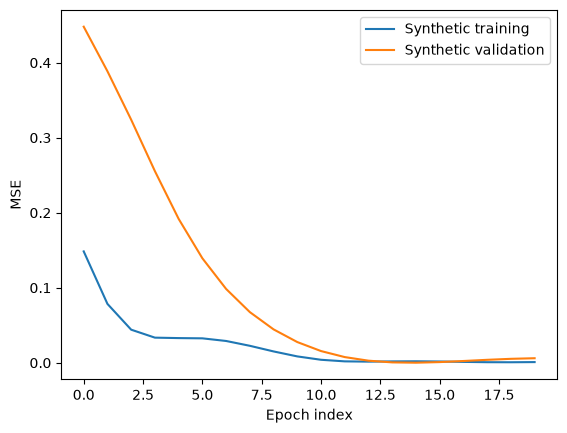

In [8]:
toy_dir = ROOT / 'outputs/phase3-tensorflow-lstm-fundamentals' / datetime.now(timezone.utc).strftime('run-%Y%m%dT%H%M%S%fZ')
toy_dir.mkdir(parents=True, exist_ok=False)
toy_path = toy_dir / 'best.weights.h5'
callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
             keras.callbacks.ModelCheckpoint(str(toy_path), monitor='val_loss', save_best_only=True, save_weights_only=True)]
fitted = toy.fit(toy_train, validation_data=toy_validation, epochs=20, callbacks=callbacks, verbose=0)
toy.load_weights(toy_path)
print('Weights before:', before_weights, '| restored weights:', [w.numpy() for w in toy.trainable_variables])
print('predict() output:', toy.predict(toy_validation.map(lambda x, y: x), verbose=0).ravel())
plt.plot(fitted.history['loss'], label='Synthetic training')
plt.plot(fitted.history['val_loss'], label='Synthetic validation')
plt.xlabel('Epoch index'); plt.ylabel('MSE'); plt.legend(); plt.show()

## What changes from the MLP experiment?
The MLP received nine engineered calendar/lag features and returned one hourly value per row. This model receives one demand feature across 48 steps and returns a whole next-day vector. It does not receive a weekly lag or explicit calendar features. Consequently, the models share the same evaluation targets and issuance contract, but not identical information or capacity.

Only 29 January midnight sequences are available with a 48-hour lookback. Their 696 hourly targets are not 696 independent sequence examples. More recurrent parameters and fewer sequences can make generalization difficult. Notebook 08 reports measured results rather than assuming LSTM is better.